Vorhersage des Zahlungsausfallrisikos mit Machine Learning

Forschungsfrage:

Kann man anhand von Kundendaten wie Einkommen, Kreditwürdigkeit und bisherigem Zahlungsverhalten das Zahlungsausfallrisiko vorhersagen?

Warum ist das interessant?

Beim BNPL-Verfahren (Buy Now, Pay Later) können Kunden Produkte sofort kaufen und später bezahlen. Für Anbieter entsteht dadurch das Risiko, dass Kunden nicht vertragsgemäß zahlen.

 **2. Ziel**

Ziel des Projekts ist es, mithilfe von Machine Learning vorherzusagen, wie hoch das Zahlungsausfallrisiko eines BNPL-Kunden ist.

Dafür werden Kundendaten wie Einkommen, Kreditwürdigkeit, bestehende Schulden und bisheriges Zahlungsverhalten analysiert.

Das Modell soll Kunden verschiedenen Risikoklassen zuordnen, damit BNPL-Anbieter mögliche Zahlungsausfälle frühzeitig erkennen und bessere Kreditentscheidungen treffen können.

In [ ]:
import pandas as pd  # Daten laden
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("../Data/BNPL_Financial_Default_Risk_Dataset.csv")

print(data.head())


In [59]:
print(data.shape)             # Anzahl der Zeilen und Spalten

(10000, 11)


Damit kann man feststellen,dass der Datensatz 10000 Kundenbeobachtungen und 11 Spalten hat.

In [ ]:
print(data.info())            # Datentypen und fehlende Werte

Für unser Projekt verwenden wir einen Datensatz mit 10.000 Kundenbeobachtungen. Er enthält Informationen über das Alter, Einkommen, die Kreditwürdigkeit und das bisherige Zahlungsverhalten. Unser Ziel ist es, das Zahlungsausfallrisiko zu analysieren.(ob kunden wie geplant die Rechnung bezahlen werden)

In [97]:

print(data.describe())        # Statistische Kennzahlen

                Age     Income_USD  Credit_Score  Total_BNPL_Active_Loans  \
count  10000.000000   10000.000000  10000.000000             10000.000000   
mean      34.248300   54121.895800    663.949400                 2.317000   
std       12.911441   29350.130276     75.094214                 1.854469   
min       18.000000    5000.000000    300.000000                 0.000000   
25%       23.000000   23182.000000    622.000000                 1.000000   
50%       31.000000   58596.000000    673.000000                 2.000000   
75%       43.000000   76482.250000    716.000000                 3.000000   
max       64.000000  139452.000000    850.000000                10.000000   

       Total_BNPL_Debt_USD  Average_Transaction_Value_USD  
count         10000.000000                   10000.000000  
mean            348.805100                     331.807700  
std             315.096249                     264.360624  
min               0.000000                      10.000000  
25%   

In [ ]:
print(data.columns.tolist())  # Alle Spaltennamen

Unsere Feature und Bedeutungen

Age	                             Alter
Employment_Status	             Beschäftigungsstatus
Income_USD	                     Einkommen
Credit_Score	                 Kreditwürdigkeit
Total_BNPL_Active_Loans  	     Anzahl aktiver BNPL-Kredite
Total_BNPL_Debt_USD	             Gesamtschulden
Late_Payment_History	         Frühere Zahlungsverzögerungen
Shopping_Category_Most_Frequent	 Häufigste Einkaufskategorie
Average_Transaction_Value_USD	 Durchschnittlicher Einkaufswert
Default_Risk	                 Zielvariable (Target)
Costumer_ID                      Kundenkennug

In [90]:
print(data.isnull().sum())  # Fehlende Werte pro Spalten

Customer_ID                        0
Age                                0
Employment_Status                  0
Income_USD                         0
Credit_Score                       0
Total_BNPL_Active_Loans            0
Total_BNPL_Debt_USD                0
Late_Payment_History               0
Shopping_Category_Most_Frequent    0
Average_Transaction_Value_USD      0
Default_Risk                       0
dtype: int64


In [75]:
print(data.duplicated().sum())  # Doppelte Zeilen zählen

0


In [89]:
data_white = data.copy()
data_white["Credit_Score"] = data_white["Credit_Score"].fillna(data_white["Credit_Score"].median())
data_white["Income_USD"] = data_white["Income_USD"].fillna(data["Income_USD"].median())
print(data.isnull().sum())

Customer_ID                        0
Age                                0
Employment_Status                  0
Income_USD                         0
Credit_Score                       0
Total_BNPL_Active_Loans            0
Total_BNPL_Debt_USD                0
Late_Payment_History               0
Shopping_Category_Most_Frequent    0
Average_Transaction_Value_USD      0
Default_Risk                       0
dtype: int64


Bei der Datenanalyse haben wir fehlende Werte im Einkommen und Credit Score festgestellt. Für unsere explorative Analyse verwenden wir eine Median-Imputation, weil der Median weniger empfindlich gegenüber Ausreißern ist

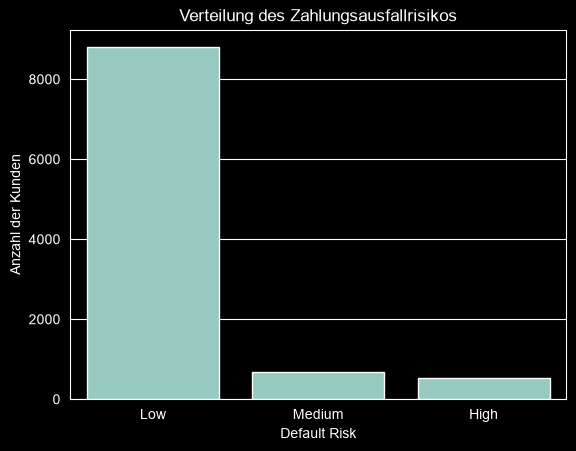

In [91]:
sns.countplot(
    data=data,
    x="Default_Risk"
)  # Anzahl der Kunden je Risikoklasse

plt.title("Verteilung des Zahlungsausfallrisikos")
plt.xlabel("Default Risk")
plt.ylabel("Anzahl der Kunden")
plt.show()

Das Diagramm zeigt ,wie viele Kunden zu jeder Risikoklasse gehören.
Dem kann man entnehmen , das die Mehrheit an Kunden ein niedriges Ausfallrisiko bei Rückgaben haben und zwar sind die Anzahl der Kunden für mittleres und hohes Risiko gering,aber ist schon etwas, denn jeder muss seine Rechnungen immer und pünktlicht(ca. 350 Kunden).

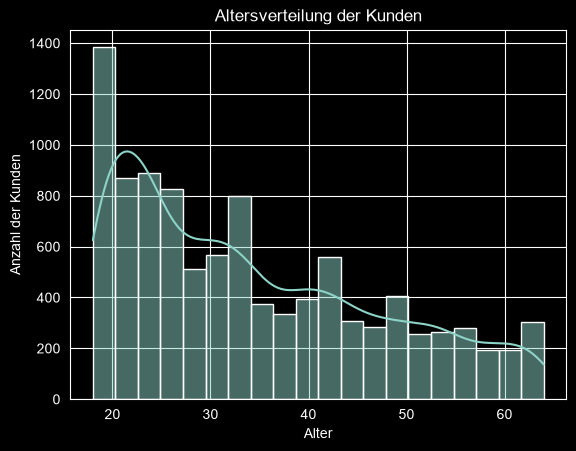

In [92]:
sns.histplot(
    data=data,
    x="Age",
    bins=20,
    kde=True
)  # Altersverteilung darstellen

plt.title("Altersverteilung der Kunden")
plt.xlabel("Alter")
plt.ylabel("Anzahl der Kunden")
plt.show()

Es zeigt, wie häufig Kunden bestimmter Altersgruppen im Datensatz vorkommen.
Es kann bemerkt werden, dass jüngere Kunden am meistens dieses Angebot "nach 30 Tagen bezahlen" nutzen.

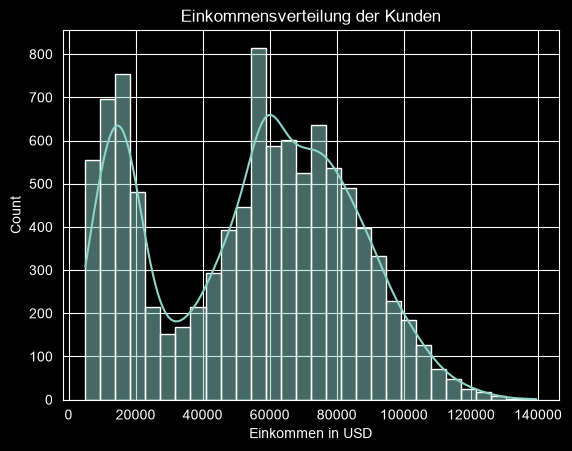

In [93]:
sns.histplot(
    data=data,
    x="Income_USD",
    bins=30,
    kde=True
)  # Einkommensverteilung

plt.title("Einkommensverteilung der Kunden")
plt.xlabel("Einkommen in USD")
plt.show()

Die Analyse zeigt, dass das durchschnittliche Einkommen der Kunden bei ungefähr 53.981 USD liegt. Gleichzeitig gibt es erhebliche Unterschiede zwischen niedrigen und hohen Einkommen. Daher untersuchen wir im nächsten Schritt, ob das Einkommen mit dem Zahlungsausfallrisiko zusammenhängt

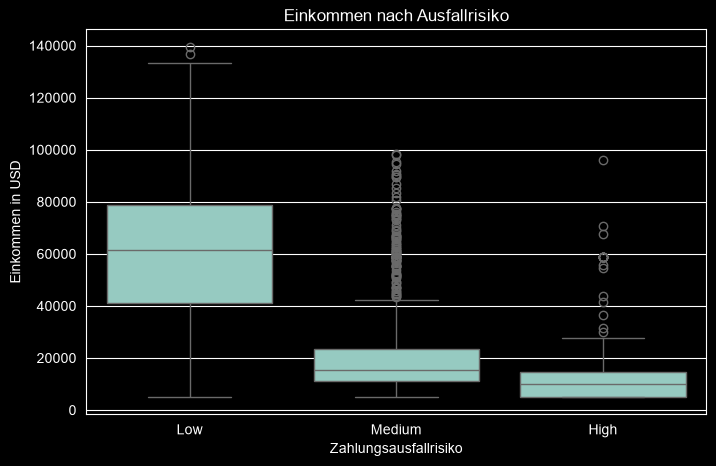

In [95]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Default_Risk",  # Zielvariable
    y="Income_USD"     # Einkommen
)

plt.title("Einkommen nach Ausfallrisiko")
plt.xlabel("Zahlungsausfallrisiko")
plt.ylabel("Einkommen in USD")
plt.show()

Wir vergleichen die Einkommensverteilungen der verschiedenen Risikoklassen, um festzustellen, ob das Einkommen ein relevantes Merkmal für die Vorhersage des Zahlungsausfallrisikos sein könnte(Nur Behauptungen muss noch bestätigt werden)
damit könnten wir sagen , dass kunden mit nidriegem Einkommen ein höheres Zahlungsausfallrisiko besitzen.

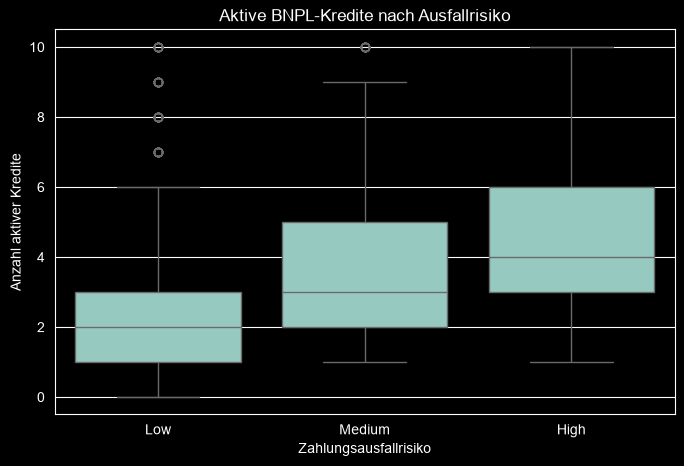

In [96]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Default_Risk",            # Zielvariable
    y="Total_BNPL_Active_Loans"  # Aktive Kredite
)

plt.title("Aktive BNPL-Kredite nach Ausfallrisiko")
plt.xlabel("Zahlungsausfallrisiko")
plt.ylabel("Anzahl aktiver Kredite")
plt.show()

Anhand den daten könnte man ebenso schließen , dass kunden mit einer großen anzahl an aktiven Krediten größere Chancen für einen Ausfall ihrer Zahlungen haben.

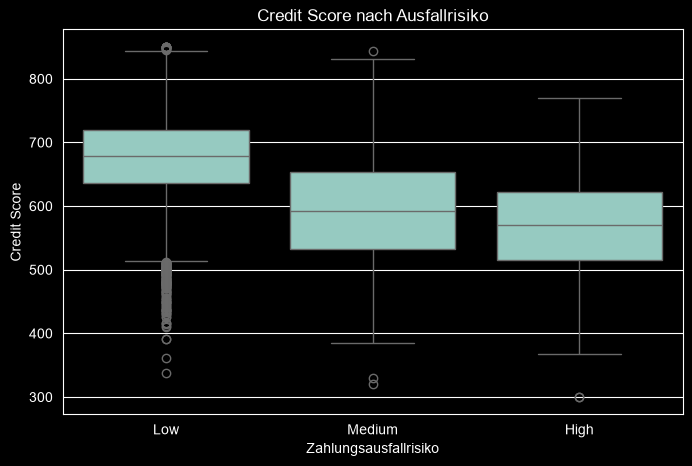

In [105]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Default_Risk",  # Zielvariable
    y="Credit_Score"    # Kreditwürdigkeit
)

plt.title("Credit Score nach Ausfallrisiko")
plt.xlabel("Zahlungsausfallrisiko")
plt.ylabel("Credit Score")
plt.show()

Je niedriger die Credit_score sind , umso höher ist das Zahlungsausfallrisiko ist.

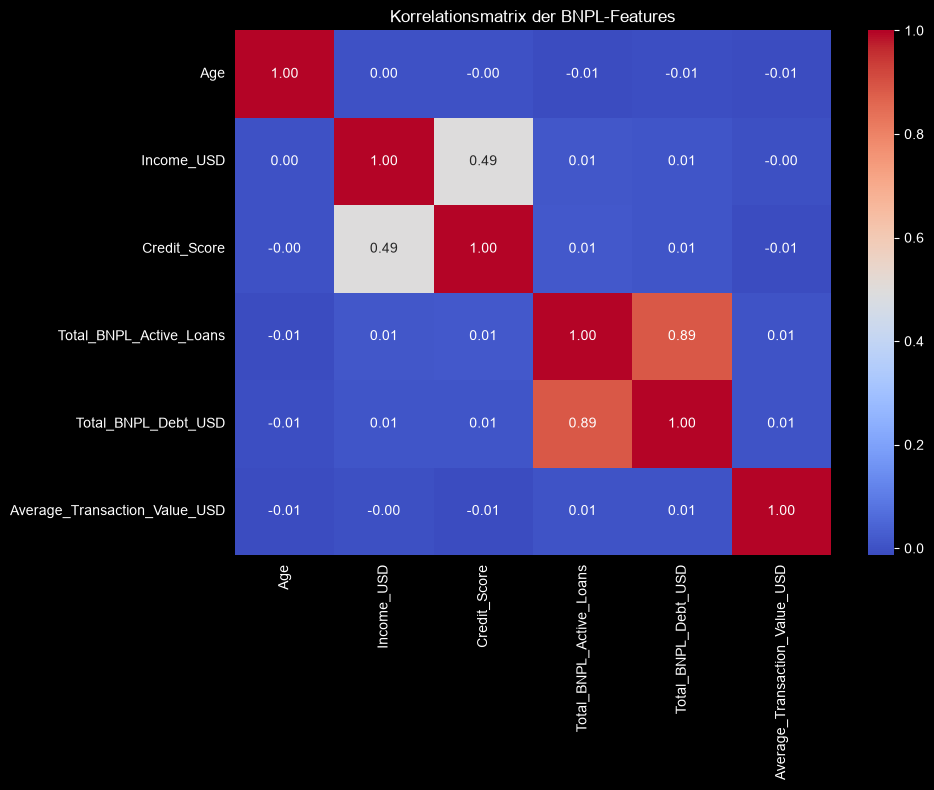

In [104]:
features = [
    "Age",
    "Income_USD",
    "Credit_Score",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD",
    "Average_Transaction_Value_USD"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    data[features].corr(),  # Korrelationen berechnen
    annot=True,                   # Werte anzeigen
    cmap="coolwarm",              # Farbskala
    fmt=".2f"                     # Zwei Nachkommastellen
)

plt.title("Korrelationsmatrix der BNPL-Features")
plt.tight_layout()
plt.show()

Aktive BNPL-Kredite: r = 0,89
Das ist der stärkste Zusammenhang in deinem Datensatz.

Je mehr aktive BNPL-Kredite ein Kunde besitzt, desto höher sind tendenziell seine gesamten BNPL-Schulden.

Das ist wirtschaftlich nachvollziehbar: Mehr laufende Finanzierungen können mit einer höheren Gesamtschuld verbunden sein.


###welche Erkenntnisse für die Vorhersage von Zahlungsausfällen relevant sind.

# ML Canvas – BNPL Financial Default Risk Prediction

**1. Problem**
BNPL-Anbieter riskieren Zahlungsausfälle, wenn Kunden ihre Raten nicht bezahlen.

**2. Ziel**
Das Zahlungsausfallrisiko eines Kunden möglichst zuverlässig vorhersagen.

**3. Zielgruppe**
BNPL-Anbieter und Mitarbeitende im Risikomanagement.

**4. Daten**
Alter, Einkommen, Credit Score, bestehende BNPL-Kredite und bisheriges Zahlungsverhalten.

**5. Target (Zielvariable)**
`Default_Risk` – das vorherzusagende Zahlungsausfallrisiko.

**6. ML-Methode**
Überwachtes Lernen (Supervised Learning): Klassifikation, beispielsweise mithilfe einer logistischen Regression.

**7. Erfolgsmessung**
Precision, Recall, F1-Score und Confusion Matrix.

**8. Nutzen**
Zahlungsausfallrisiken frühzeitig erkennen und fundierte Kreditentscheidungen unterstützen.